In [1]:
from playground import Playground

[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO: Successfully loaded OpenSpiel environments: 16.
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_backgammon
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_checkers
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_chess
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_connect_four
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_gin_rummy
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_go
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_goofspiel
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_hearts
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_hex
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_matching_pennies_3p
[kaggle_environments.envs.

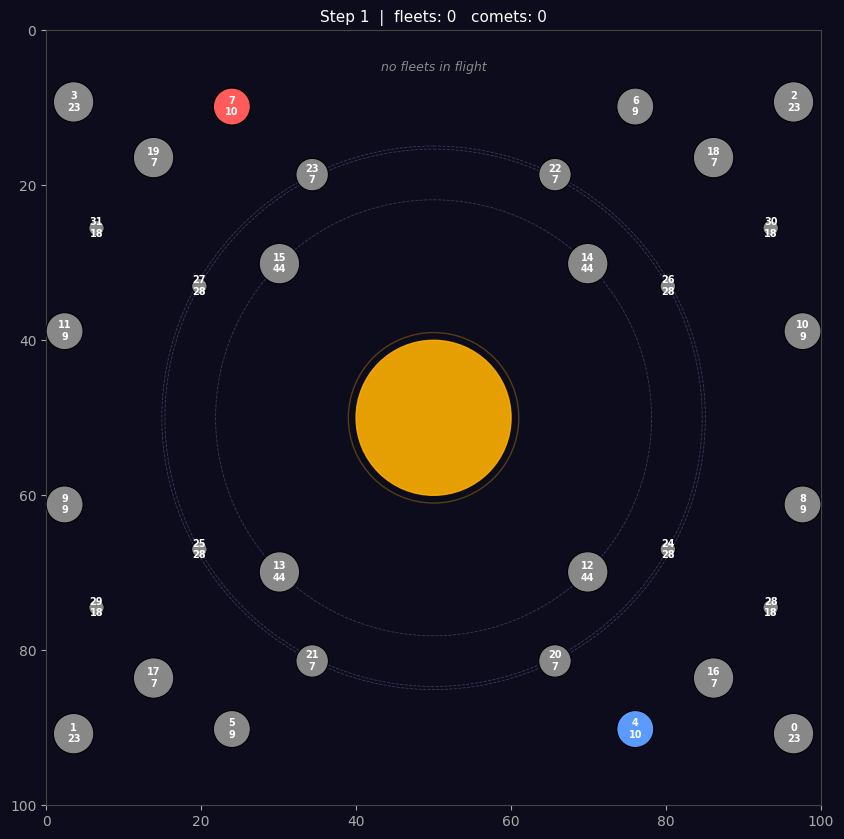

 ID  Owner  Kind         X       Y  Ships  Prod   rSun
------------------------------------------------------------
  4  ME     static    76.0    90.2     10     4   47.9
 12  Neut   rot       69.9    69.9     44     5   28.1
 13  Neut   rot       30.1    69.9     44     5   28.1
 14  Neut   rot       69.9    30.1     44     5   28.1
 15  Neut   rot       30.1    30.1     44     5   28.1
 20  Neut   rot       65.7    81.4      7     3   35.1
 21  Neut   rot       34.3    81.4      7     3   35.1
 22  Neut   rot       65.7    18.6      7     3   35.1
 23  Neut   rot       34.3    18.6      7     3   35.1
 24  Neut   rot       80.2    67.0     28     1   34.7
 25  Neut   rot       19.8    67.0     28     1   34.7
 26  Neut   rot       80.2    33.0     28     1   34.7
 27  Neut   rot       19.8    33.0     28     1   34.7
  0  Neut   static    96.4    90.8     23     5   61.8
  1  Neut   static     3.6    90.8     23     5   61.8
  2  Neut   static    96.4     9.2     23     5   61.8
  3 

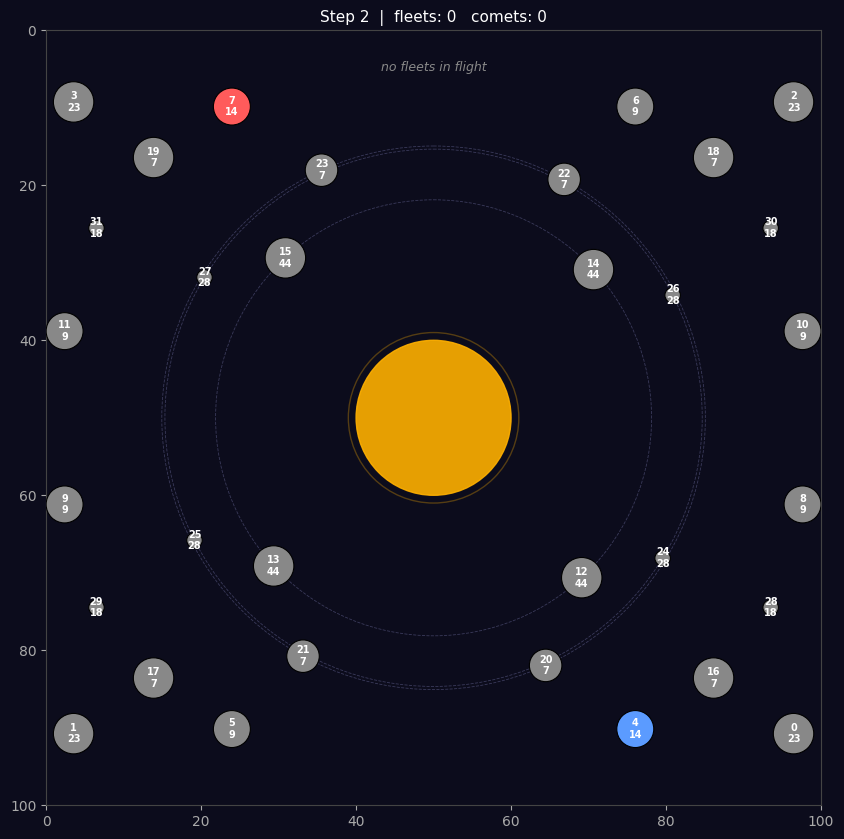

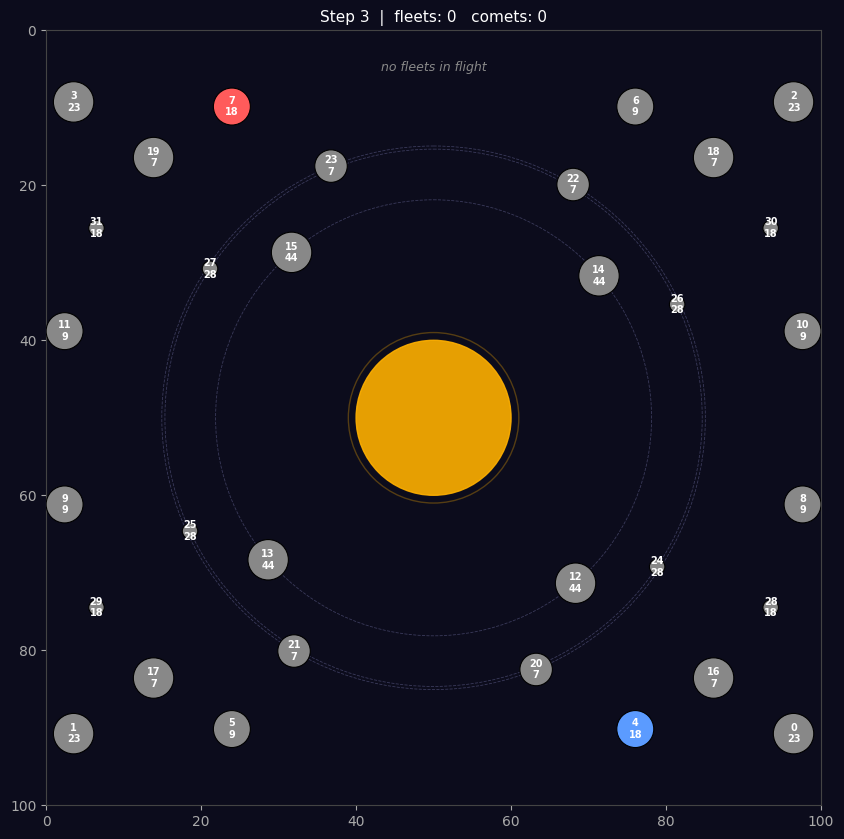

In [2]:
pg = Playground()
pg.render()
pg.planet_table()         # 0 senin, 7 nötr olsun
pg.launch(0, 7, ships=8)  # otomatik açı + ETA print
pg.step()                 # tur ilerlet
pg.render()               # filo havada, kesikli yörünge görünür
pg.step(); pg.render()    # ETA dolunca filo yok olur, gezegen sahibi değişir

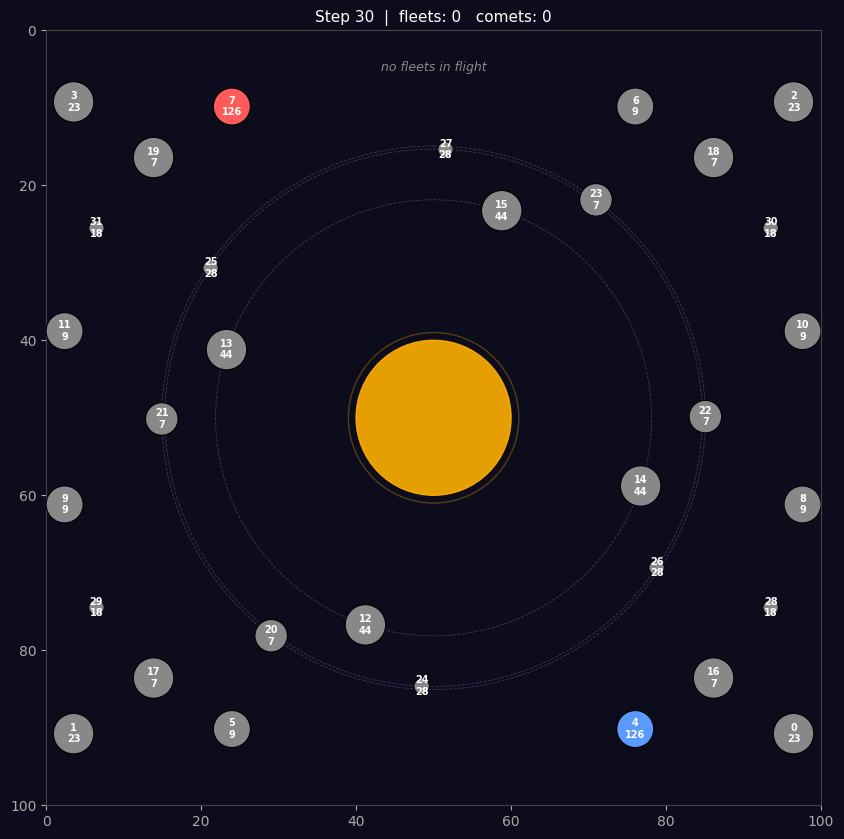

In [29]:
pg.step(); pg.render() 

In [30]:
result = pg.launch(src_id=4, tgt_id=8, ships=20) 

P0 step 30: planet 4 -> 8, 20 ships, angle=-53.3°, ETA=14.88 turns (expected arrival ~ step 45)


(no fleets in flight)


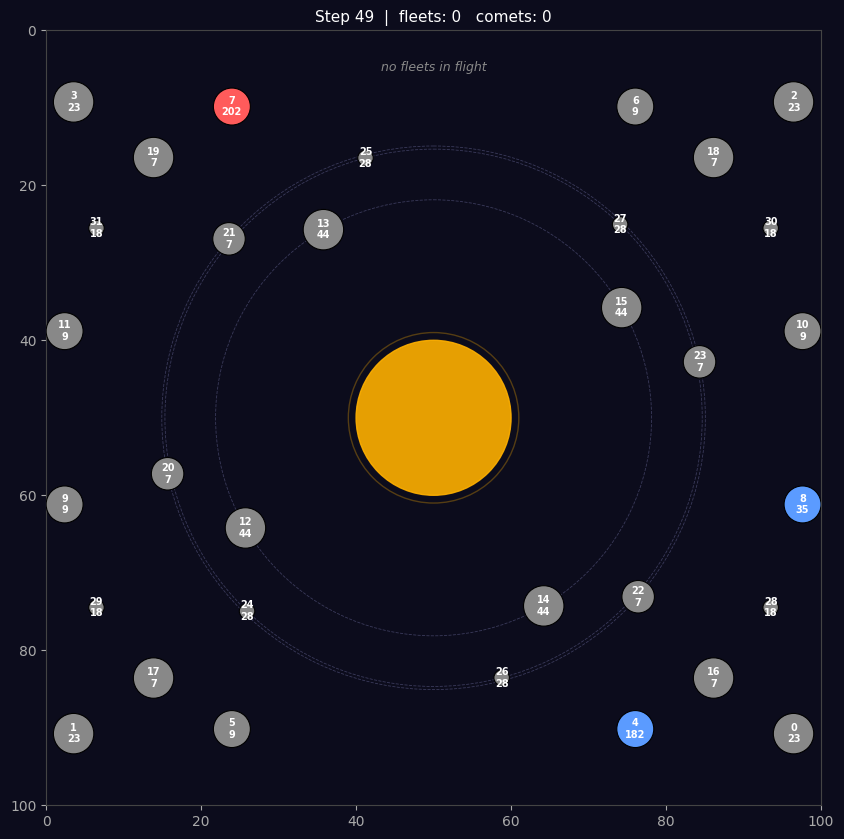

In [49]:
pg.step()                        # filo şimdi env'de spawn oldu
pg.fleet_table()                 # filo tablosu — ID, ships, speed gözükür
pg.render()                      # üçgen ikonu görünür, "fleets: 1" başlıkta


In [91]:
result = pg.launch(src_id=4, tgt_id=15, ships=20) 

P0 step 80: planet 4 -> 15, 20 ships, angle=-120.0°, ETA=8.14 turns (expected arrival ~ step 89)


(no fleets in flight)


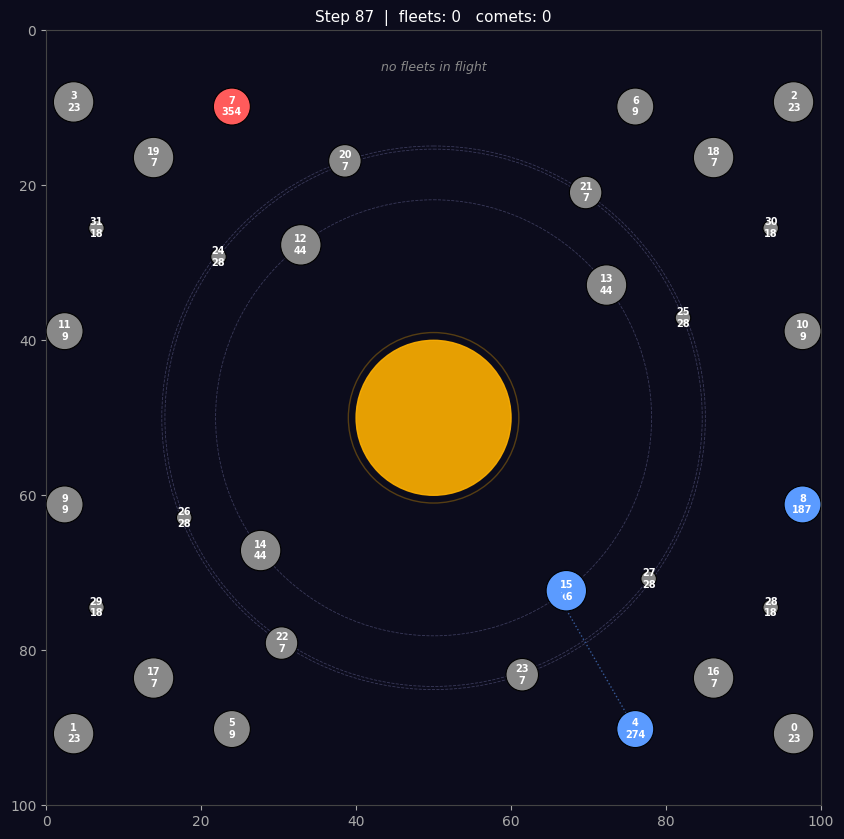

In [98]:
pg.step()                        # filo şimdi env'de spawn oldu
pg.fleet_table()                 # filo tablosu — ID, ships, speed gözükür
pg.render()                      # üçgen ikonu görünür, "fleets: 1" başlıkta

In [83]:
from navigation import find_intercepts, crosses_sun, path_collision, fleet_speed
import math

me = pg.obs["player"]
omega = pg.obs["angular_velocity"]
ps = pg.planets()
src = next(p for p in ps if p.id == 4)
tgt = next(p for p in ps if p.id == 15)
ships = 20

cands = find_intercepts(src, tgt, ships, omega, max_results=6)
print(f"Speed(20 ships) = {fleet_speed(ships):.3f}")
print(f"Intercept candidates: {len(cands)}")

for i, (t_star, ix, iy) in enumerate(cands):
    a = math.atan2(iy - src.y, ix - src.x)
    sx = src.x + math.cos(a) * (src.radius + 0.1)
    sy = src.y + math.sin(a) * (src.radius + 0.1)
    sun_hit = crosses_sun(sx, sy, ix, iy)
    blocker = path_collision(
        src, a, ships, t_star,
        [p for p in ps if p.id not in (src.id, tgt.id)],
        omega,
    )
    print(f"  #{i}: t*={t_star:6.2f}  intercept=({ix:5.1f},{iy:5.1f})  "
          f"sun={sun_hit}  blocker={blocker}")

Speed(20 ships) = 2.428
Intercept candidates: 1
  #0: t*=  8.87  intercept=( 70.4, 69.4)  sun=False  blocker=23
